In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arrow
from typing import Tuple, List, Set

from robot import Point, Robot, random_robots, circle_positions, greatest_distance_to_nearest_target

### Generate randomly positioned robots

In [2]:
num_robots = 8
x_min = -10
x_max = 10
y_min = -10
y_max = 10

robots = random_robots(num_robots, x_min, x_max, y_min, y_max)

### Generate target positions 

In [3]:
# generate points on the outline of a circle
target_positions = circle_positions(num_robots, 3)

### Assign Robots to targets
- $R$ - Set of Robots
- $T$ - Set of target points
- $RT$ - Set of robots that achieved their target point
- $RN$ - Set of robots that did not achieve their target point
- $TN$ - Set of target points that are not assigned to robots
- $TR$ - Set of points of the target formation that are assigned to robots
- $p$ - priority of robot

<br>
Before target assignement:

$RN \equiv R$, $RT = \emptyset$, $TN \equiv T$, $TR = \emptyset$
<br><br>
Algorithm:
<br><br>
$p := 1$
<br>
while($TN \neq \emptyset$)
1. find $R_i \in RN$ whose distance to the nearest $T_j \in TN$ is greater then for any other robot in $RN$
2. assign target $T_j$ to robot $R_i$
3. move $R_i$ from set $RN$ to set $RT$ and move $T_i$ from $TN$ to $TR$
4. assign priority $p$ to robot $R_i$
5. $p := p + 1$

end

In [4]:
def target_assignement_strategy_1(robots: List[Robot], targets: List[Point]) -> Set[Robot]:
    """
    Assignes targets and priorities to robots
    """
    RT = set()
    RN = set()
    TN = set()
    TR = set()

    # initial assignement
    RN.update(robots)
    TN.update(targets)

    # initial priority
    p = 1

    # do target assignement
    while len(TN) != 0:
        # find robot whose distance to the nearest target is greater than for any other robot
        robot, target = greatest_distance_to_nearest_target(RN, TN)

        # set robot target
        robot.set_target(target)

        # move robot from RN to RT
        RN.remove(robot)
        RT.add(robot)

        # move target from TN to TR
        TN.remove(target)
        TR.add(target)

        # assign priority to robot
        robot.set_priority(p)

        # update priority
        p += 1

    # return the robots with their targets assigned
    return RT

In [6]:
assigned_robots = target_assignement_strategy_1(robots, target_positions)

### plot results

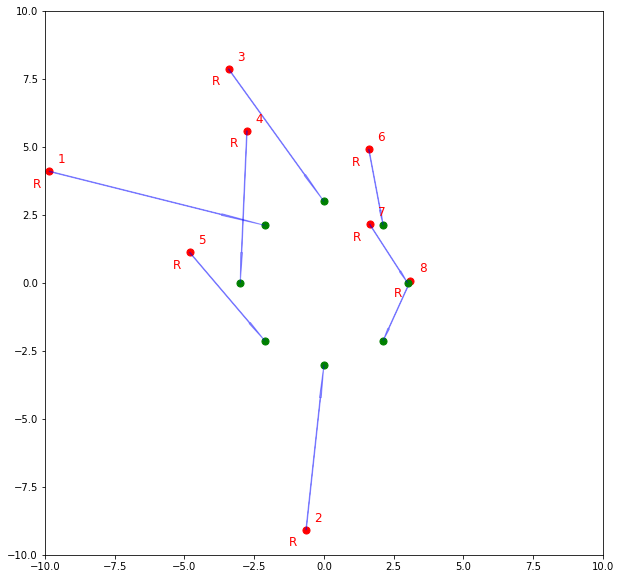

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))

for robot in assigned_robots:
    # plot robot
    ax.scatter(robot.position.x, robot.position.y, color='red', s=50)

    # plot target
    ax.scatter(robot.target.x, robot.target.y, color='green', s=50)

    # plot priority
    ax.text(robot.position.x + 0.3, robot.position.y + 0.3, robot.priority, fontsize=12, color='red')
    ax.text(robot.position.x - 0.6, robot.position.y - 0.6, "R", fontsize=12, color='red')

    # plot arrow from robot to target
    arrow = Arrow(
        robot.position.x,
        robot.position.y,
        robot.target.x - robot.position.x,
        robot.target.y - robot.position.y,
        color = 'blue',
        width = 0.1,
        alpha=0.4
    )
    ax.add_patch(arrow)


ax.set_xlim([-10, 10])
ax.set_ylim([-10, 10])

plt.show()